---
title: "L5-10 · Noise, encoding, and error correction"
short_title: "Noise, encoding, and error correction"
subtitle: "Noise is a channel that shrinks the Bloch ball; error correction is a different channel, built from encoding, parity measurements and conditional recovery, that undoes a chosen set of errors and turns a physical error rate $p$ into a logical rate of order $p^2$."
description: "Describe depolarizing, phase-flip and bit-flip noise by their action on the Bloch vector, and show how the three-qubit code detects and corrects one bit flip without reading the encoded state."
tags: [level-5, coursebook]
---

(lesson-l5-10)=

:::{div}
:class: qcai-meta
![Level 5 icon](../../_static/icons/qicon-level-5.svg) **Level 5 · Advanced undergraduate** · about 110 minutes  
**Big idea.** Noise is a channel that shrinks the Bloch ball; error correction is a different channel, built from encoding, parity measurements and conditional recovery, that undoes a chosen set of errors and turns a physical error rate $p$ into a logical rate of order $p^2$.  
**Before this lesson.** [L5-06](#lesson-l5-06), [L5-09](#lesson-l5-09)  
**Lab.** [Noise and quantum channels](../../labs/07-noise-channels.ipynb)
:::

## What you will be able to do

- Compute the Bloch-vector map and the purity after depolarizing, phase-flip and bit-flip channels, and choose measurements that tell them apart.
- Trace the three-qubit bit-flip code through encoding, a single $X$ error, measurement of $Z_1Z_2$ and $Z_2Z_3$, and recovery, and explain why the syndrome reveals nothing about $\alpha$ and $\beta$.
- Derive $p_L = 3p^2 - 2p^3$ for independent flips, check it by Monte Carlo, and show that encoding helps exactly when $p < 1/2$.
- Explain why a phase flip defeats the bit-flip code, how Hadamard conjugation gives the phase-flip code, and how Shor's nine-qubit code combines the two.

## Why this matters

Classical memory fights noise by repetition: store a bit three times and take a majority vote. Every part of that recipe seems to fail for qubits. An unknown state cannot be copied. Reading the copies to vote would collapse the superposition you are trying to protect. And quantum errors are continuous: a tiny unwanted rotation is an error too, so there seem to be infinitely many errors to fix. It was not obvious that quantum information could be protected at all.

Shor's 1995 nine-qubit code showed otherwise [@shor1995]. The repair has three ideas, and this lesson builds each one. Copy the basis labels, not the state: $\alpha|000\rangle + \beta|111\rangle$ is entangled, not three copies. Measure only parities, which reveal where an error sits but not what is stored. And let that measurement turn a continuous error into one of a few discrete ones. Today's devices are still noisy [@nisq], so knowing exactly what a code does, and under which noise model, is the difference between a real improvement and a misleading number.

:::{dropdown} Key terms

**Depolarizing channel**
: $\mathcal{D}_p(\rho) = (1 - p)\rho + p\,I/2$: with weight $p$ the state is replaced by the maximally mixed state; the Bloch vector shrinks to $(1 - p)\vec r$.

**Dephasing (phase flip)**
: $\rho \mapsto (1 - q)\rho + q\,Z\rho Z$: coherence between $|0\rangle$ and $|1\rangle$ decays while $Z$-basis populations stay the same.

**Code space**
: The subspace that holds the logical qubit; for the bit-flip code it is spanned by $|0_L\rangle = |000\rangle$ and $|1_L\rangle = |111\rangle$.

**Syndrome**
: The outcomes of measuring check operators such as $Z_1Z_2$ and $Z_2Z_3$; they identify a correctable error without revealing the logical state.

**Recovery**
: The correction applied conditional on the syndrome, here an $X$ on the qubit the syndrome points to.

**Logical error rate**
: The probability $p_L$ that the whole procedure ends with a wrong logical operation applied, for a stated noise model.

:::


In [1]:
import sys, pathlib, subprocess
here = pathlib.Path.cwd()
root = next((p for p in [here, *here.parents] if (p / "qcai").is_dir()), None)
if root is None:  # for example on Google Colab: fetch the course's small teaching package
    root = pathlib.Path("quantum-causal-ai")
    if not root.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pozapas/quantum-causal-ai.git", str(root)], check=True)
    root = root.resolve()
sys.path.insert(0, str(root))
from qcai.viz import show as _show, show_mpl as _show_mpl
from qcai.lessonfigs import l5_10 as _lessonfigs

## Noise as a channel on the Bloch ball

A noise process on one qubit is a quantum channel, a completely positive trace-preserving map with Kraus operators as in [L5-06](#lesson-l5-06). Writing $\rho = \tfrac12(I + \vec r\cdot\vec\sigma)$ as in [L5-05](#lesson-l5-05), every channel below acts on the Bloch vector by a simple linear map, so its effect can be seen as a deformation of the Bloch ball.

:::{prf:definition} Three standard noise channels
:label: def-l5-10-channels
For $0 \le p \le 1$ and $0 \le q \le 1$:

- **Depolarizing**: $\mathcal{D}_p(\rho) = (1 - p)\rho + p\,I/2$, Kraus operators $\sqrt{1 - 3p/4}\,I$, $\sqrt{p/4}\,X$, $\sqrt{p/4}\,Y$, $\sqrt{p/4}\,Z$.
- **Phase flip (dephasing)**: $\mathcal{Z}_q(\rho) = (1 - q)\rho + q\,Z\rho Z$, Kraus operators $\sqrt{1 - q}\,I$, $\sqrt q\,Z$.
- **Bit flip**: $\mathcal{X}_q(\rho) = (1 - q)\rho + q\,X\rho X$, Kraus operators $\sqrt{1 - q}\,I$, $\sqrt q\,X$.

Here $p$ is a mixing weight and $q$ is a flip probability. The depolarizing channel is the same as in [L5-06](#lesson-l5-06); the dephasing channel of [L5-06](#lesson-l5-06), with parameter $p$, is $\mathcal{Z}_q$ with $q = p/2$. The two conventions differ: since $I/2 = \tfrac14(\rho + X\rho X + Y\rho Y + Z\rho Z)$ for every qubit state, $\mathcal{D}_p$ applies each of $X$, $Y$, $Z$ with probability $p/4$ [@nielsenchuang].
:::

:::{prf:proposition} Bloch-vector form of the channels
:label: prop-l5-10-bloch
$\mathcal{D}_p$ maps $\vec r \mapsto (1 - p)\vec r$. $\mathcal{Z}_q$ maps $(r_x, r_y, r_z) \mapsto \big((1 - 2q)r_x, (1 - 2q)r_y, r_z\big)$. $\mathcal{X}_q$ maps $(r_x, r_y, r_z) \mapsto \big(r_x, (1 - 2q)r_y, (1 - 2q)r_z\big)$.
:::

:::{prf:proof}
$I/2$ has Bloch vector $0$, so the mixture $(1 - p)\rho + pI/2$ has Bloch vector $(1 - p)\vec r$. Conjugation by a Pauli matrix keeps that matrix and flips the sign of the other two, because distinct Pauli matrices anticommute: $ZXZ = -X$, $ZYZ = -Y$, $ZZZ = Z$. So $Z\rho Z$ has Bloch vector $(-r_x, -r_y, r_z)$, and $(1 - q)\vec r + q(-r_x, -r_y, r_z) = \big((1 - 2q)r_x, (1 - 2q)r_y, r_z\big)$. The bit flip is the same computation with $X$ in place of $Z$.
:::

$$
\mathcal{D}_p:\ \vec r \mapsto (1 - p)\,\vec r, \qquad \mathcal{Z}_q:\ (r_x, r_y, r_z) \mapsto \big((1 - 2q)\,r_x,\ (1 - 2q)\,r_y,\ r_z\big)
$$ (eq-l5-10-bloch)

:::{figure} ../../_static/animations/l5_10_bloch_contraction.mp4
:alt: A Bloch sphere with six state arrows shrinks evenly under depolarizing noise, then is squeezed into a cigar along z by a phase flip, and into a cigar along x by a bit flip.
:width: 100%

Three channels, three deformations of the Bloch ball. Depolarizing shrinks it evenly; a phase flip squeezes it toward the $z$ axis; a bit flip squeezes it toward the $x$ axis.
:::

:::{dropdown} What the animation shows
A translucent Bloch sphere carries six arrows to the states $|0\rangle$, $|1\rangle$, $|{+}\rangle$, $|{-}\rangle$, $|{+i}\rangle$, $|{-i}\rangle$. First depolarizing noise with $p = 0.5$ shrinks the sphere and every arrow to half length, $\vec r \mapsto (1 - p)\vec r$. The sphere is restored. Then a phase flip with $q = 0.25$ shrinks the $x$ and $y$ directions by the factor $1 - 2q = 0.5$ while the $z$ axis is untouched: the sphere becomes an ellipsoid elongated along $z$, and the arrows to $|0\rangle$ and $|1\rangle$ keep full length. The text notes that $Z$-basis counts cannot see this noise. Finally a bit flip with $q = 0.25$ shrinks the $y$ and $z$ directions by $1 - 2q$, giving an ellipsoid elongated along $x$ in which $|{+}\rangle$ and $|{-}\rangle$ are untouched.
:::

:::{prf:example} Purity after depolarizing
:label: ex-l5-10-depol
Apply $\mathcal{D}_{0.2}$ to $|0\rangle\langle 0|$: the output is $0.8\operatorname{diag}(1, 0) + 0.2\operatorname{diag}(\tfrac12, \tfrac12) = \operatorname{diag}(0.9, 0.1)$, with purity $0.81 + 0.01 = 0.82$ and Bloch vector $(0, 0, 0.8)$. In the flip-probability convention this is not a 20 percent chance of an error: each of $X$, $Y$, $Z$ occurs with probability $0.05$.
:::

:::{tip} Same counts, different channels
Send $|{+}\rangle$ through $\mathcal{D}_{0.5}$ or through $\mathcal{Z}_{0.25}$: both outputs have Bloch vector $(0.5, 0, 0)$, so no measurement on that output can tell them apart. Send $|0\rangle$ instead: $\mathcal{D}_{0.5}$ gives $r_z = 0.5$ while $\mathcal{Z}_{0.25}$ leaves $r_z = 1$. Characterizing a channel needs several input states and several measurement bases, which is the tomography of [L5-09](#lesson-l5-09) applied to a process.
:::

## The three-qubit bit-flip code

Two CNOT gates with qubit 1 as control send $(\alpha|0\rangle + \beta|1\rangle)|00\rangle$ to $\alpha|000\rangle + \beta|111\rangle$. Qubits are ordered $1, 2, 3$ from left to right. This is not three copies: $(\alpha|0\rangle + \beta|1\rangle)^{\otimes 3}$ contains terms such as $\alpha^2\beta|001\rangle$, while the encoded state is entangled and has only two terms. What gets repeated is the basis label, which a CNOT can copy, and not the unknown state, which no operation can copy.

:::{prf:definition} Bit-flip code and its syndrome
:label: def-l5-10-code
The **bit-flip code** stores $\alpha|0\rangle + \beta|1\rangle$ as $\alpha|0_L\rangle + \beta|1_L\rangle$ with $|0_L\rangle = |000\rangle$, $|1_L\rangle = |111\rangle$. Its **syndrome** is the pair of outcomes of the commuting parity observables $Z_1Z_2$ and $Z_2Z_3$, each $\pm 1$, measured with two ancilla qubits as in the figure. Outcome $+1$ means the two qubits agree.
:::


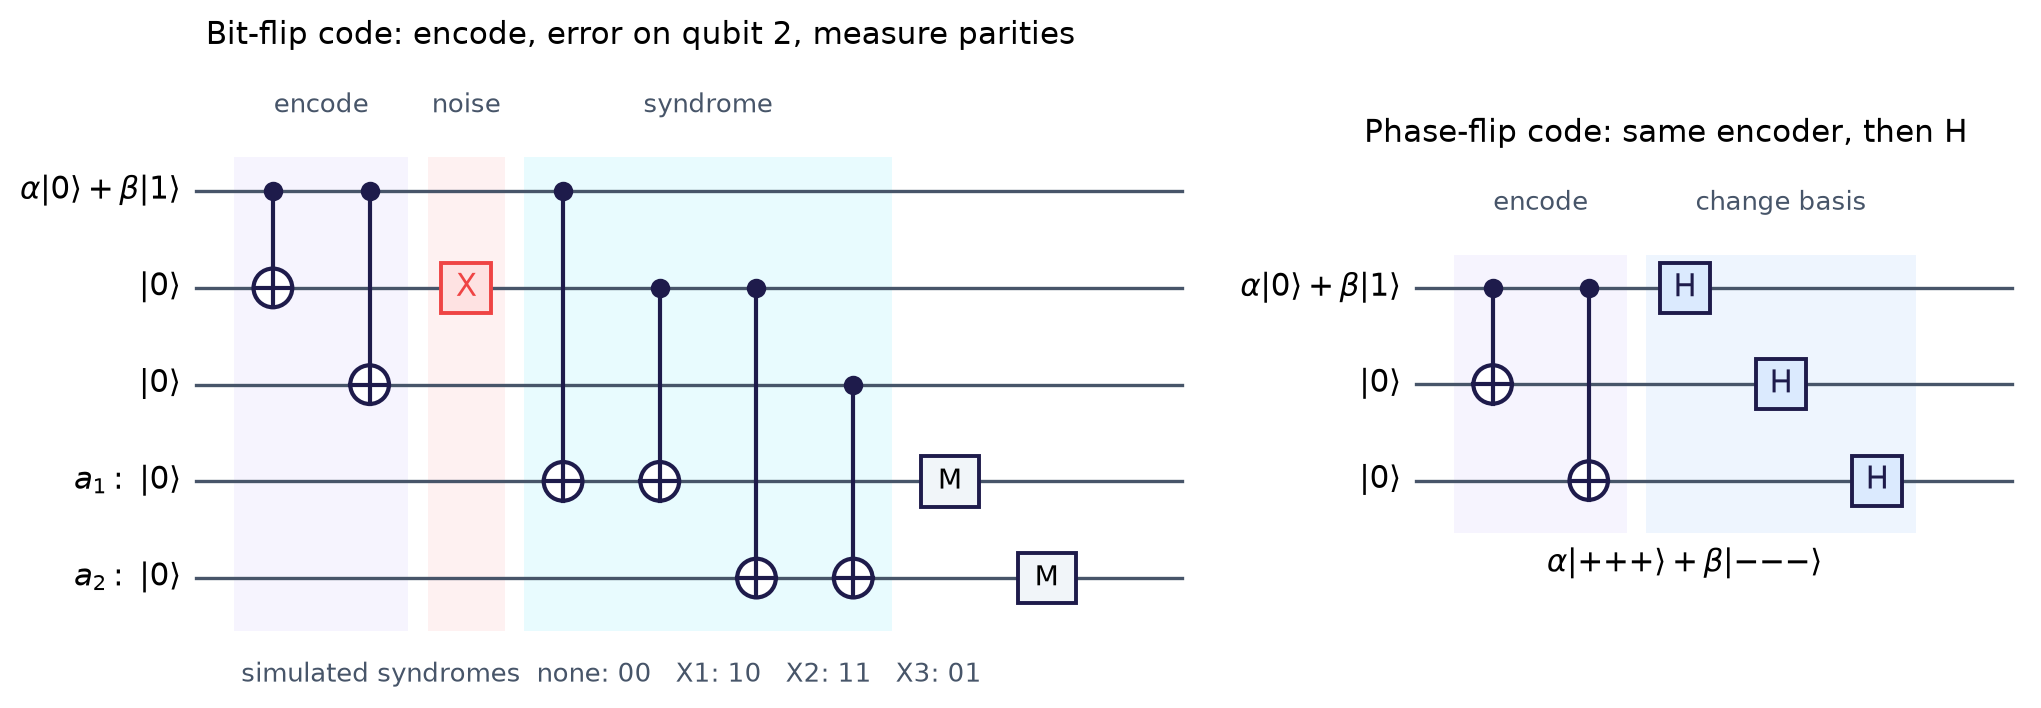

In [2]:
_show_mpl(_lessonfigs.code_circuits())

*Left: encoding, an $X$ error on qubit 2, and syndrome extraction; ancilla $a_1$ records the parity of qubits 1 and 2, ancilla $a_2$ that of qubits 2 and 3. The syndromes printed underneath come from simulating this exact gate list. Right: the phase-flip code uses the same encoder followed by a Hadamard on each qubit.*

Writing ancilla bit $0$ for parity $+1$ and $1$ for parity $-1$:

| error | state after error | $Z_1Z_2$ | $Z_2Z_3$ | ancillas | recovery |
|---|---|---|---|---|---|
| none | $\alpha\lvert 000\rangle + \beta\lvert 111\rangle$ | $+1$ | $+1$ | 00 | none |
| $X_1$ | $\alpha\lvert 100\rangle + \beta\lvert 011\rangle$ | $-1$ | $+1$ | 10 | $X_1$ |
| $X_2$ | $\alpha\lvert 010\rangle + \beta\lvert 101\rangle$ | $-1$ | $-1$ | 11 | $X_2$ |
| $X_3$ | $\alpha\lvert 001\rangle + \beta\lvert 110\rangle$ | $+1$ | $-1$ | 01 | $X_3$ |

:::{prf:theorem} The bit-flip code corrects any single bit flip
:label: thm-l5-10-bitflip
Let $E \in \{I, X_1, X_2, X_3\}$. For every $\alpha, \beta$, measuring $Z_1Z_2$ and $Z_2Z_3$ on $E(\alpha|000\rangle + \beta|111\rangle)$ gives the syndrome in the table with certainty, leaves the state unchanged, and applying the listed recovery returns exactly $\alpha|000\rangle + \beta|111\rangle$.
:::

:::{prf:proof}
Both $|000\rangle$ and $|111\rangle$ are $+1$ eigenvectors of $Z_1Z_2$ and $Z_2Z_3$. Since $X_j$ anticommutes with $Z_j$ and commutes with $Z_k$ for $k \ne j$, each check operator $M$ satisfies $MX_j = \pm X_j M$, so $X_j|000\rangle$ and $X_j|111\rangle$ are eigenvectors of $M$ with the same sign $\pm 1$. Hence $E(\alpha|000\rangle + \beta|111\rangle)$ is itself an eigenvector of both checks, with the eigenvalues in the table, whatever $\alpha$ and $\beta$ are. Measuring an observable on one of its eigenvectors gives that eigenvalue with probability 1 and does not change the state. The four syndromes differ, so the syndrome determines $E$, and applying $E$ again restores the code state because $E^2 = I$.
:::

:::{figure} ../../_static/animations/l5_10_bitflip_code.mp4
:alt: A circuit with three data wires and two ancilla wires: two CNOTs encode, a red X hits qubit 2, four CNOTs copy parities to the ancillas, the ancillas read 1 and 1, and an X on qubit 2 restores the state, with the state written beside each stage.
:width: 100%

Encode, suffer one bit flip, read two parities, correct. The ancillas learn which qubit disagrees and nothing about $\alpha$ or $\beta$.
:::

:::{dropdown} What the animation shows
Five horizontal wires: data qubits 1, 2, 3 and ancillas $a_1$, $a_2$. The first qubit holds $\alpha|0\rangle + \beta|1\rangle$. Two CNOTs light up and the state line reads $\alpha|000\rangle + \beta|111\rangle$. A red $X$ strikes qubit 2 and the state becomes $\alpha|010\rangle + \beta|101\rangle$. Four CNOTs copy the parity of qubits 1 and 2 onto $a_1$ and of qubits 2 and 3 onto $a_2$; the two checks $Z_1Z_2$ and $Z_2Z_3$ both read $-1$, shown as ancilla bits 1 and 1, and a lookup table points to qubit 2. The data state is unchanged by these measurements, because both of its terms have the same parities. An $X$ on qubit 2 then restores $\alpha|000\rangle + \beta|111\rangle$. A closing line notes that the syndrome would be the same for every $\alpha$ and $\beta$.
:::

:::{important} What the syndrome does not learn
The syndrome outcome has probability 1 for every encoded state, so it carries no information about $\alpha$ or $\beta$. That is exactly why measuring it does not disturb them. A measurement of $Z_1$ alone, by contrast, would return $0$ with probability $|\alpha|^2$ and destroy the superposition.
:::

## How much does the code help?

Take the simplest noise model: each of the three qubits suffers an $X$ independently with probability $p$, and encoding, syndrome measurement and recovery are perfect. With no flips or one flip the procedure restores the state. With two flips, say on qubits 1 and 2, the syndrome is the one for $X_3$; the recovery applies $X_3$ and the net effect is $X_1X_2X_3$, which maps $|000\rangle \leftrightarrow |111\rangle$: a logical $X$. With three flips the syndrome is trivial and the logical $X$ stays. So the procedure fails exactly when at least two qubits flip:

$$
p_L = 3p^2(1 - p) + p^3 = 3p^2 - 2p^3
$$ (eq-l5-10-pl)

:::{prf:proposition} When encoding helps
:label: prop-l5-10-break-even
For $0 < p < 1/2$, $p_L < p$; at $p = 1/2$ they are equal; for $1/2 < p < 1$, $p_L > p$. For small $p$, $p_L \approx 3p^2$.
:::

:::{prf:proof}
$p - p_L = p - 3p^2 + 2p^3 = p(1 - 3p + 2p^2) = p(1 - p)(1 - 2p)$. On $0 < p < 1$ the factors $p$ and $1 - p$ are positive, so the sign is that of $1 - 2p$. For small $p$ the term $2p^3$ is negligible next to $3p^2$.
:::

:::{figure} ../../_static/animations/l5_10_logical_rate.mp4
:alt: The formula for the logical error rate simplifies term by term to 3p squared minus 2p cubed; then a point sweeps along the curve and the no-code line, which cross at p equals one half.
:width: 100%

Counting failure patterns gives $3p^2 - 2p^3$. Below $p = 1/2$ the curve lies under the line $p_L = p$, and the gap is $p(1-p)(1-2p)$.
:::

:::{dropdown} What the animation shows
The derivation appears line by line: the probability of at least two flips is $\binom{3}{2}p^2(1 - p) + p^3$, which becomes $3p^2 - 3p^3 + p^3$ and then $3p^2 - 2p^3$, with matching terms sliding into place. Then axes appear with $p$ from 0 to 1 horizontally. A dashed gray line shows $p_L = p$ (no code) and a violet curve shows $3p^2 - 2p^3$. A tracker sweeps $p$ from 0 to 1 while two dots ride the line and the curve and a live readout shows both values; at $p = 0.1$ it pauses on $p_L = 0.028$. The curve stays below the line until the two meet at $p = 1/2$, after which the code makes things worse. The factored gap $p - p_L = p(1-p)(1-2p)$ is written at the end.
:::


In [3]:
_show(_lessonfigs.code_explorer())

**Explore.** Move the slider to set the physical flip probability $p$. Left: the logical error rate of the three-qubit code (violet) against no code (dashed), with Monte Carlo estimates. Right: the probabilities of 0, 1, 2 and 3 flips; the red bars are the failures.

:::{dropdown} What the figure shows
The left panel plots $p$ and $3p^2 - 2p^3$ for $p$ from 0 to 0.6, with orange Monte Carlo points from 4000 simulated runs at each $p$ lying on the curve and a red marker at the chosen $p$. The right panel shows the binomial probabilities $(1-p)^3$, $3p(1-p)^2$, $3p^2(1-p)$ and $p^3$ for 0, 1, 2 and 3 flips; the last two bars, colored red, add up to the logical error rate. At $p = 0.1$ these are 0.729, 0.243, 0.027 and 0.001.
:::

Monte Carlo check of [](#eq-l5-10-pl) with a seeded generator. The estimates agree with the formula to within about two standard errors.


In [4]:
import numpy as np

# Independent bit flips with probability p on each of three qubits; perfect syndrome and recovery.
# The decoder fails exactly when two or three qubits flip.
rng = np.random.default_rng(6)
trials = 200_000
print('   p   Monte Carlo   3p^2 - 2p^3   standard error')
for p in (0.01, 0.05, 0.1, 0.2, 0.3, 0.5):
    flips = rng.random((trials, 3)) < p
    est = (flips.sum(axis=1) >= 2).mean()
    se = np.sqrt(est * (1 - est) / trials)
    print(f'{p:5.2f}   {est:.5f}       {3 * p**2 - 2 * p**3:.5f}       {se:.5f}')

   p   Monte Carlo   3p^2 - 2p^3   standard error
 0.01   0.00032       0.00030       0.00004
 0.05   0.00728       0.00725       0.00019
 0.10   0.02772       0.02800       0.00037
 0.20   0.10360       0.10400       0.00068
 0.30   0.21623       0.21600       0.00092
 0.50   0.49951       0.50000       0.00112


A statevector run of the code for one arbitrary logical state: each single bit flip gives a definite syndrome and is undone exactly; a phase flip $Z_2$ goes unseen and leaves fidelity $(|\alpha|^2 - |\beta|^2)^2 = 0.0784$.


In [5]:
from qcai import science as sci

I2, X, Z = sci.I2, sci.X, sci.Z
P0, P1 = np.diag([1, 0]).astype(complex), np.diag([0, 1]).astype(complex)

def op(single, j):
    """A one-qubit operator on qubit j of three (qubit 1 is the leftmost tensor factor)."""
    mats = [I2, I2, I2]
    mats[j] = single
    return sci.kron(*mats)

CX12 = sci.kron(P0, I2, I2) + sci.kron(P1, X, I2)          # control qubit 1, target qubit 2
CX13 = sci.kron(P0, I2, I2) + sci.kron(P1, I2, X)          # control qubit 1, target qubit 3
Z1Z2, Z2Z3 = op(Z, 0) @ op(Z, 1), op(Z, 1) @ op(Z, 2)
recovery = {(1, 1): np.eye(8), (-1, 1): op(X, 0), (-1, -1): op(X, 1), (1, -1): op(X, 2)}

a, b = 0.6, 0.8j                                           # an arbitrary normalized logical state
logical = CX13 @ CX12 @ np.kron(np.kron([a, b], [1, 0]), [1, 0])
print('encoded amplitudes on |000> and |111>:', logical[0], logical[7])
for name, E in [('none', np.eye(8)), ('X1', op(X, 0)), ('X2', op(X, 1)), ('X3', op(X, 2)), ('Z2', op(Z, 1))]:
    psi = E @ logical
    s = tuple(int(round(np.real(np.vdot(psi, M @ psi)))) for M in (Z1Z2, Z2Z3))   # each is exactly +1 or -1
    fixed = recovery[s] @ psi
    print(f'error {name:4s}  syndrome (Z1Z2, Z2Z3) = {s}   fidelity after recovery {abs(np.vdot(logical, fixed))**2:.4f}')

encoded amplitudes on |000> and |111>: (0.6+0j) 0.8j
error none  syndrome (Z1Z2, Z2Z3) = (1, 1)   fidelity after recovery 1.0000
error X1    syndrome (Z1Z2, Z2Z3) = (-1, 1)   fidelity after recovery 1.0000
error X2    syndrome (Z1Z2, Z2Z3) = (-1, -1)   fidelity after recovery 1.0000
error X3    syndrome (Z1Z2, Z2Z3) = (1, -1)   fidelity after recovery 1.0000
error Z2    syndrome (Z1Z2, Z2Z3) = (1, 1)   fidelity after recovery 0.0784


:::{prf:remark} What the number 3p^2 - 2p^3 measures
:label: rem-l5-10-meaning
$p_L$ is the probability that the procedure applies a logical $X$. How much damage that does depends on the stored state: $X_L$ leaves $(|0_L\rangle + |1_L\rangle)/\sqrt2$ unchanged and flips $|0_L\rangle$ completely. Equivalently, under this noise model the encoded qubit experiences a bit-flip channel with flip probability $3p^2 - 2p^3$ (the challenge exercise proves this). With noisy syndrome measurements, correlated errors, or other error types, the formula no longer applies.
:::

## Phase errors and Shor's nine-qubit code

A phase flip $Z_j$ on any qubit sends $\alpha|000\rangle + \beta|111\rangle$ to $\alpha|000\rangle - \beta|111\rangle$. Both checks $Z_1Z_2$ and $Z_2Z_3$ commute with $Z_j$, so the syndrome is $(+1, +1)$ and the error is invisible; worse, it is a logical phase flip. The bit-flip code protects one kind of error only.

:::{prf:proposition} Hadamard turns phase flips into bit flips
:label: prop-l5-10-hadamard
$HZH = X$ and $HXH = Z$, with $H|0\rangle = |{+}\rangle$, $H|1\rangle = |{-}\rangle$. Consequently the **phase-flip code** $|0_L\rangle = |{+}{+}{+}\rangle$, $|1_L\rangle = |{-}{-}{-}\rangle$, obtained by applying $H^{\otimes 3}$ after the bit-flip encoder, corrects any single $Z_j$ using the checks $X_1X_2$ and $X_2X_3$.
:::

:::{prf:proof}
Direct multiplication gives $HZH = X$ [@ibm]; conjugating by $H$ again gives $HXH = Z$ since $H^2 = I$. A phase flip on the encoded state satisfies $Z_j H^{\otimes 3}|\psi\rangle = H^{\otimes 3}X_j|\psi\rangle$, so in the rotated frame it is a bit flip of the bit-flip code. The checks transform as $H^{\otimes 3}(Z_1Z_2)H^{\otimes 3} = X_1X_2$ and likewise for $Z_2Z_3$, and the recovery $X_j$ becomes $Z_j$. [](#thm-l5-10-bitflip) then applies word for word.
:::

:::{prf:definition} Shor's nine-qubit code
:label: def-l5-10-shor
Encode with the phase-flip code, then encode each of its three qubits with the bit-flip code [@shor1995]:

$|0_L\rangle = \tfrac{1}{2\sqrt2}\big(|000\rangle + |111\rangle\big)^{\otimes 3}$, $\quad |1_L\rangle = \tfrac{1}{2\sqrt2}\big(|000\rangle - |111\rangle\big)^{\otimes 3}$.

Bit flips are found by $Z_iZ_j$ parity checks inside each block of three; phase flips are found by comparing the signs of neighboring blocks with the six-qubit checks $X_1\cdots X_6$ and $X_4\cdots X_9$.
:::

:::{figure} ../../_static/animations/l5_10_shor_code.mp4
:alt: A phase flip slips past the bit-flip code's parity checks; the Hadamard swaps the roles of X and Z; then nine qubits arranged as three blocks of three show a bit flip caught inside a block and a phase flip caught by comparing block signs.
:width: 100%

Why one repetition is not enough, and how nesting two repetitions in different bases protects against both kinds of error.
:::

:::{dropdown} What the animation shows
First the bit-flip code state $\alpha|000\rangle + \beta|111\rangle$ receives a $Z$ on qubit 2; the state becomes $\alpha|000\rangle - \beta|111\rangle$, and both parity checks $Z_1Z_2$ and $Z_2Z_3$ still read $+1$, so the error is missed. Next the identities $HZH = X$ and $HXH = Z$ appear, and the code words become $|{+}{+}{+}\rangle$ and $|{-}{-}{-}\rangle$, in which a $Z$ is a bit flip of the signs. Finally nine circles appear in three blocks of three, labeled with the block states $|000\rangle \pm |111\rangle$. A red $X$ on qubit 5 is caught by the checks $Z_4Z_5$ and $Z_5Z_6$ inside the middle block. A red $Z$ on qubit 7 flips the sign of the third block, and the comparisons of block signs, $X_1\cdots X_6 = +1$ and $X_4\cdots X_9 = -1$, point to the third block. The closing line states that any single-qubit error is a combination of $I$, $X$, $Z$ and $XZ$, so correcting these four corrects every single-qubit error.
:::

:::{prf:theorem} Discretization of errors
:label: thm-l5-10-discrete
Suppose a code with syndrome measurement and recovery corrects each error in a set $\{E_a\}$. Then it corrects every linear combination $E = \sum_a c_a E_a$ acting on a code state. In particular, a code that corrects $I$, $X_j$, $Z_j$ and $X_jZ_j$ on qubit $j$ corrects every operator on qubit $j$, since these four matrices span all $2\times 2$ matrices ($Y_j = iX_jZ_j$).
:::

:::{prf:proof}
Proof sketch, for the case in which different $E_a$ give different syndromes (the Shor code also has errors with equal syndromes, such as $Z_1$ and $Z_2$, but they act identically on the code space, so the same argument works). Let $|\psi\rangle$ be a code state. Then $E|\psi\rangle = \sum_a c_a E_a|\psi\rangle$, and $E_a|\psi\rangle$ lies in the eigenspace of the syndrome observables labeled by syndrome $a$. Measuring the syndrome projects $E|\psi\rangle$ onto one term, giving $E_a|\psi\rangle$ up to normalization with probability proportional to $|c_a|^2\langle\psi|E_a^\dagger E_a|\psi\rangle$, and the recovery for that syndrome returns $|\psi\rangle$. Every outcome ends in the same state, so the procedure corrects $E$ [@nielsenchuang; @preskill].
:::

```{mermaid}
graph TD
  L["one logical qubit"] --> P["phase-flip code: three blocks"]
  P --> B1["block 1: qubits 1 2 3"]
  P --> B2["block 2: qubits 4 5 6"]
  P --> B3["block 3: qubits 7 8 9"]
  B1 --> C1["Z parity checks find X errors"]
  B2 --> C2["Z parity checks find X errors"]
  B3 --> C3["Z parity checks find X errors"]
  P --> S["X checks on block pairs find Z errors"]
```

*Shor's code is a concatenation: an outer phase-flip code over three blocks, and an inner bit-flip code inside each block.*

:::{prf:remark} The Knill-Laflamme condition
:label: rem-l5-10-kl
A code with projector $P$ onto its code space can correct the error set $\{E_a\}$ if and only if $PE_a^\dagger E_bP = c_{ab}P$ for some numbers $c_{ab}$ forming a Hermitian matrix [@nielsenchuang]. The condition says that errors never map different code words to overlapping or differently scaled images, so no error reveals logical information. The next cell checks it numerically.
:::

The Knill-Laflamme condition holds for the bit-flip code with $\{I, X_1, X_2, X_3\}$ and fails once $Z_1$ is added; it holds for Shor's code with all 28 single-qubit Pauli errors (the identity and $X$, $Y$, $Z$ on each of nine qubits).


In [6]:
# Knill-Laflamme check: P E_a^dagger E_b P must be a multiple of P for every pair of errors.
code = np.zeros((8, 2), dtype=complex)
code[0, 0] = code[7, 1] = 1                                # columns |000> and |111>
P = code @ code.conj().T

def knill_laflamme(errors):
    for Ea in errors:
        for Eb in errors:
            M = P @ Ea.conj().T @ Eb @ P
            if not np.allclose(M, (np.trace(M) / 2) * P):
                return False
    return True

flips = [np.eye(8), op(X, 0), op(X, 1), op(X, 2)]
print('bit-flip code, errors {I, X1, X2, X3}:', knill_laflamme(flips))
print('bit-flip code, add Z1:               ', knill_laflamme(flips + [op(Z, 0)]))

# Shor's nine-qubit code against every single-qubit Pauli error (1 + 27 errors), using vectors only.
def on(v, M, j, n=9):
    t = np.moveaxis(np.tensordot(M, v.reshape([2] * n), axes=([1], [j])), 0, j)
    return t.reshape(-1)

g, h = np.eye(8)[0], np.eye(8)[7]
blk_p, blk_m = (g + h) / np.sqrt(2), (g - h) / np.sqrt(2)
L0 = np.kron(np.kron(blk_p, blk_p), blk_p)
L1 = np.kron(np.kron(blk_m, blk_m), blk_m)
errs = [None] + [(M, j) for j in range(9) for M in (X, sci.Y, Z)]
images = [(L0, L1) if e is None else (on(L0, *e), on(L1, *e)) for e in errs]
ok = all(abs(np.vdot(u[0], v[1])) < 1e-12 and abs(np.vdot(u[1], v[0])) < 1e-12
         and abs(np.vdot(u[0], v[0]) - np.vdot(u[1], v[1])) < 1e-12 for u in images for v in images)
print('Shor code, all 28 single-qubit Pauli errors:', ok)

bit-flip code, errors {I, X1, X2, X3}: True
bit-flip code, add Z1:                False
Shor code, all 28 single-qubit Pauli errors: True


:::{caution} Correction is not yet fault tolerance
Everything here assumes that encoding, syndrome measurement and recovery are perfect and that errors strike qubits independently. Real syndrome circuits are noisy and can spread one fault to several qubits. Fault-tolerant constructions handle that, and they work only when physical error rates are below a threshold that depends on the noise model and the code [@nielsenchuang; @preskill]. Current devices operate with noise of this kind and without full fault tolerance [@nisq], so a logical error rate should always be reported together with the complete procedure and the noise model.
:::

## Worked example

:::{admonition} Logical error rate at p = 0.1
:class: tip

Each of the three qubits of the bit-flip code flips independently with probability $p = 0.1$; syndrome measurement and recovery are perfect. Find the probability of each number of flips, the logical error rate, and the improvement factor over an unencoded qubit. Repeat the last two for $p = 0.01$.

1. Binomial probabilities: 0 flips $(0.9)^3 = 0.729$; 1 flip $3(0.1)(0.9)^2 = 0.243$; 2 flips $3(0.1)^2(0.9) = 0.027$; 3 flips $(0.1)^3 = 0.001$. They add to 1.
2. Zero or one flip is corrected; two or three flips end in a logical $X$. So $p_L = 0.027 + 0.001 = 0.028$, matching $3p^2 - 2p^3 = 0.03 - 0.002$.
3. Improvement: $p/p_L = 0.1/0.028 \approx 3.6$. The break-even check $p(1-p)(1-2p) = 0.1 \cdot 0.9 \cdot 0.8 = 0.072 = p - p_L$ is positive.
4. At $p = 0.01$: $p_L = 3(0.0001) - 2(0.000001) = 0.000298$, an improvement of $0.01/0.000298 \approx 34$.

**Result.** $p_L = 0.028$ at $p = 0.1$ and $0.000298$ at $p = 0.01$: because $p_L \approx 3p^2$, the benefit grows as the physical error rate falls, under this noise model only.
:::

## Exercises

**1. (Core)** Apply $\mathcal{D}_{0.4}$ to $|1\rangle\langle 1|$. Give the output matrix, the $Z$-basis probabilities, and the purity.

:::{dropdown} Solution
$0.6\operatorname{diag}(0, 1) + 0.4\operatorname{diag}(\tfrac12, \tfrac12) = \operatorname{diag}(0.2, 0.8)$. The probabilities are 0.2 for outcome 0 and 0.8 for outcome 1, and the purity is $0.04 + 0.64 = 0.68$. The Bloch vector shrank from $(0, 0, -1)$ to $(0, 0, -0.6)$.
:::

**2. (Core)** An $X$ hits qubit 3 of $\alpha|000\rangle + \beta|111\rangle$. Write the state, the values of $Z_1Z_2$ and $Z_2Z_3$, and the recovery.

:::{dropdown} Solution
The state is $\alpha|001\rangle + \beta|110\rangle$. Qubits 1 and 2 agree, so $Z_1Z_2 = +1$; qubits 2 and 3 disagree, so $Z_2Z_3 = -1$. The syndrome points to qubit 3, and applying $X_3$ restores $\alpha|000\rangle + \beta|111\rangle$.
:::

**3. (Stretch)** Flips hit qubits 1 and 2. Follow the syndrome and the recovery and say what logical operation results.

:::{dropdown} Solution
The state is $\alpha|110\rangle + \beta|001\rangle$. $Z_1Z_2 = +1$ and $Z_2Z_3 = -1$, the syndrome of $X_3$. The recovery applies $X_3$, giving $\alpha|111\rangle + \beta|000\rangle = X_L(\alpha|0_L\rangle + \beta|1_L\rangle)$: a logical bit flip, which is why two flips count as a failure in [](#eq-l5-10-pl).
:::

**4. (Stretch)** Show that $\mathcal{Z}_q$ leaves all $Z$-basis probabilities unchanged. The state $|{+}\rangle$ is sent through an unknown phase-flip channel and $\langle X\rangle$ is measured to be 0.8. Find $q$.

:::{dropdown} Solution
By [](#prop-l5-10-bloch), $r_z$ is unchanged, and the $Z$-basis probabilities are $(1 \pm r_z)/2$. For $|{+}\rangle$, $r_x = 1$ becomes $1 - 2q = 0.8$, so $q = 0.1$.
:::

**5. (Challenge)** Show that under independent bit flips with probability $p$ and perfect correction, the encoded qubit undergoes exactly the bit-flip channel $\rho_L \mapsto (1 - p_L)\rho_L + p_L X_L\rho_L X_L$ with $p_L = 3p^2 - 2p^3$, where $X_L = X_1X_2X_3$.

:::{dropdown} Solution
Each flip pattern $F \subseteq \{1, 2, 3\}$ occurs with probability $p^{|F|}(1 - p)^{3 - |F|}$ and applies $X_F = \prod_{j \in F}X_j$. For $|F| \le 1$ the syndrome identifies $F$ and recovery gives $I$. For $|F| = 2$ the syndrome is that of the missing qubit $k$, and recovery gives $X_kX_F = X_1X_2X_3 = X_L$. For $|F| = 3$ the syndrome is trivial and the net operation is $X_L$. Because every outcome ends in either $I$ or $X_L$ on the code space, the overall map is $(1 - p_L)\rho_L + p_L X_L\rho_L X_L$ with $p_L = 3p^2(1 - p) + p^3 = 3p^2 - 2p^3$.
:::

**6. (Challenge)** In Shor's code, show that $Z_1$ and $Z_2$ have the same effect on every code state, so the code can fix a phase flip in block 1 without learning which of its qubits suffered it.

:::{dropdown} Solution
$Z_1Z_2$ acts as the identity on $|000\rangle$ and on $|111\rangle$, hence on block 1 of every code word. So $Z_1|\psi_L\rangle = Z_1(Z_1Z_2)|\psi_L\rangle = Z_2|\psi_L\rangle$, using $Z_1^2 = I$. Applying $Z_1$ as the recovery undoes a $Z_2$ error as well: $Z_1Z_2|\psi_L\rangle = |\psi_L\rangle$. Codes with this property are called degenerate.
:::

## Check your understanding

**1. What does a syndrome measurement seek to reveal?**

- **A.** The values of $\alpha$ and $\beta$ to within shot noise
- **B.** Information about an error without reading the logical data
- **C.** The full unknown logical state
- **D.** Independent copies of the logical state

:::{dropdown} Show the answer
**B. Information about an error without reading the logical data**

The checks $Z_1Z_2$ and $Z_2Z_3$ take definite values on every corrupted code state, so their outcomes identify a correctable error and carry no information about $\alpha$ and $\beta$. Reading the logical state would destroy it.
:::

**2. Each qubit of the bit-flip code flips independently with probability $p = 0.1$, and correction is perfect. What is the logical error rate?**

- **A.** 0.271
- **B.** 0.1
- **C.** 0.01
- **D.** 0.028

:::{dropdown} Show the answer
**D. 0.028**

Failures need at least two flips: $3p^2(1-p) + p^3 = 0.027 + 0.001 = 0.028 = 3p^2 - 2p^3$.
:::

**3. Which single-qubit error does the three-qubit bit-flip code fail to detect?**

- **A.** $X$ on qubit 2
- **B.** $Z$ on qubit 2
- **C.** $X$ on qubit 1
- **D.** $X$ on qubit 3

:::{dropdown} Show the answer
**B. $Z$ on qubit 2**

$Z_2$ commutes with both checks $Z_1Z_2$ and $Z_2Z_3$, so the syndrome stays $(+1, +1)$, and it maps $\alpha|000\rangle + \beta|111\rangle$ to $\alpha|000\rangle - \beta|111\rangle$, a logical phase flip.
:::

**4. Is $\rho \mapsto (1 - q)\rho + qX\rho X$ with Kraus operators $\sqrt{1 - q}\,I$ and $\sqrt q\,X$ trace preserving?** *(Review of [L5-06](#lesson-l5-06))*

- **A.** Only when $q = 1/2$
- **B.** Yes, because $(1 - q)I + qX^\dagger X = I$
- **C.** No, because $X$ is not positive
- **D.** Only for diagonal $\rho$

:::{dropdown} Show the answer
**B. Yes, because $(1 - q)I + qX^\dagger X = I$**

A Kraus map is trace preserving when $\sum_k K_k^\dagger K_k = I$. Here $(1 - q)I + qX^\dagger X = (1 - q)I + qI = I$ for every $q$.
:::

## Common misconceptions

- **Encoding $\alpha|0\rangle + \beta|1\rangle$ as $\alpha|000\rangle + \beta|111\rangle$ makes three copies of the state.** Three copies would be $(\alpha|0\rangle + \beta|1\rangle)^{\otimes 3}$, with eight terms. The code state is entangled and has two; no qubit alone holds the state, and the no-cloning property is respected.
- **To correct an error you have to measure the qubits and find out what state they are in.** The code measures only parities, which have definite values on every corrupted code state. Measuring a single data qubit in the $Z$ basis would destroy the superposition.
- **Quantum errors are continuous, so no finite code can correct them.** The syndrome measurement projects a continuous error onto one of finitely many discrete errors ([](#thm-l5-10-discrete)); correcting $I$, $X$, $Z$ and $XZ$ on each qubit corrects every single-qubit error.
- **Adding more qubits to a code always lowers the error rate.** The three-qubit code helps only for $p < 1/2$ even in the ideal model, and with noisy syndrome circuits more qubits mean more places for faults. Gains require error rates below a threshold and a fault-tolerant design.

:::{caution} Scope and limits
Conventions: $\mathcal{D}_p(\rho) = (1 - p)\rho + pI/2$ uses a mixing weight, which equals applying each Pauli $X$, $Y$, $Z$ with probability $p/4$; the bit-flip and phase-flip channels use a flip probability $q$; the course helper `qcai.science.dephasing_kraus(p)` shrinks $r_x, r_y$ by $1 - p$, which is the phase flip with $q = p/2$. Qubits are ordered $1, 2, 3$ from the left of each ket. The formula $p_L = 3p^2 - 2p^3$ holds only for independent bit flips with perfect encoding, syndrome measurement and recovery; it is not a fault-tolerant analysis, and this lesson makes no claim about thresholds or about any device. The Monte Carlo and statevector results are classical simulations, not experiments.
:::

:::{seealso} Where this leads
The recovery is a channel that depends on a measurement record, an instrument in the sense of [L5-07](#lesson-l5-07). Level 6 treats channels such as these as causal mechanisms between laboratories and represents them by Choi matrices. Noise models of this kind also govern what near-term variational algorithms can achieve without error correction [@nisq].
:::

:::{dropdown} For instructors

**Why this lesson.** Error correction is where the abstract rules of channels, measurement and entanglement pay off. Students see a measurement that helps rather than harms, a reason to care about which basis noise acts in, and the first honest resource accounting: three or nine physical qubits for one logical qubit, worthwhile only below a break-even error rate [@nielsenchuang; @preskill; @shor1995].

**Teaching notes.**

- Start with the classical repetition code and ask students which steps break for qubits; list cloning, measurement and continuous errors on the board and cross each off as the lesson resolves it.
- Have students fill in the syndrome table themselves before showing the animation; the key observation is that both terms of every row have the same parities.
- Use the interactive to locate the crossing at $p = 1/2$ and then ask why real devices would need far smaller $p$ (noisy syndromes, other error types) [@nisq].

**Assessment.** The two stretch exercises test whether students can follow a syndrome through recovery, including a failure case. The first challenge exercise checks that they can turn the counting argument into a statement about channels.

**Going further.** Work through the five-qubit perfect code, or show that the three-qubit code under the depolarizing channel $\mathcal{D}_p$ on each qubit still has logical error of order $p$ because of phase errors. Shor's original paper is short and readable [@shor1995], and Nielsen and Chuang, Chapter 10, continues to stabilizer codes [@nielsenchuang].

:::

## References

This lesson draws on [@nielsenchuang; @preskill; @shor1995; @nisq; @ibm].

**Further reading.**

- [@nielsenchuang]: Chapter 10 covers the bit-flip, phase-flip and Shor codes, the Knill-Laflamme conditions and fault tolerance.
- [@shor1995]: The original nine-qubit code.
- [@preskill]: Lecture notes, chapter 7, on quantum error correction.

**Next:** [L6-01 · Quantum common causes](#lesson-l6-01)
